# Analiza podatkov Formule 1 (2018 – 2025)
### Projektna seminarska naloga pri predmetu Uvod v programiranje

---

## 1. Uvod in opis problema
Formula 1 velja za vrhunec avtomobilističnega športa, kjer odločajo stotinke sekunde, aerodinamične inovacije ter taktična natančnost ekip. 

Med sezonama **2018 in 2025** je Formula 1 doživela pomembne prelomnice:
1. **Zrelost hibridne dobe V6 (2018–2020)**: Popolna prevlada ekipe Mercedes in poskusi izziva s strani Ferrarija.
2. **Dramatičen boj za naslov leta 2021**: Neposreden in izenačen dvoboj med Lewisom Hamiltonom in Maxom Verstappnom.
3. **Uvedba novih aerodinamičnih pravil (2022–2023)**: Vrnitev t.i. "talnega učinka" (ground effect) in prevlada ekipe Red Bull Racing.
4. **Ponovna izenačenost (2024–2025)**: Izjemen vzpon McLarna (konstruktorski naslov 2024) in Ferrarija.
5. **Uvedba sobotnih sprint dirk (2021–2025)**: Format dodatnega tekmovanja z delitvijo pomembnih prvenstvenih točk.

### Zastavljena raziskovalna vprašanja
- **Prvenstvena prevlada**: Kako se je razmerje moči med Mercedesom, Red Bullom, Ferrarijem in McLarnom spreminjalo skozi leta?
- **Pomen kvalifikacij**: Kakšen je delež zmag iz najboljšega štartnega položaja (Pole position) in kako močno štartno mesto določa končno uvrstitev?
- **Postanki v boksih**: Koliko v povprečju traja postanek v boksih ter kakšne strategije menjav pnevmatik prevladujejo?
- **Hitrost na dirkališčih**: Kako so aerodinamična pravila leta 2022 vplivala na povprečne hitrosti krogov na legendarnih dirkališčih (Monza, Silverstone, Spa, Monako)?
- **Sprint dirke**: Kateri dirkači so najbolj izkoristili točkovanje na sobotnih sprint preizkušnjah?


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Nastavitev privzetega videza grafov
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['figure.titlesize'] = 16

MAPA_PODATKOV = os.path.join("podatki", "obdelani")
print("Okolje je pripravljeno. Nalaganje obdelanih podatkov...")


Okolje je pripravljeno. Nalaganje obdelanih podatkov...


In [2]:
# Nalaganje vseh CSV tabel
df_dirkaci = pd.read_csv(os.path.join(MAPA_PODATKOV, "lestvica_dirkaci.csv"))
df_konstruktorji = pd.read_csv(os.path.join(MAPA_PODATKOV, "lestvica_konstruktorji.csv"))
df_rezultati = pd.read_csv(os.path.join(MAPA_PODATKOV, "rezultati_dirk.csv"))
df_kvalifikacije = pd.read_csv(os.path.join(MAPA_PODATKOV, "kvalifikacije.csv"))
df_postanki = pd.read_csv(os.path.join(MAPA_PODATKOV, "postanki_v_boksih.csv"))
df_sprinti = pd.read_csv(os.path.join(MAPA_PODATKOV, "sprint_dirke.csv"))

print(f"Lestvica dirkačev:      {df_dirkaci.shape[0]} vrstic, {df_dirkaci.shape[1]} stolpcev")
print(f"Lestvica konstruktorjev: {df_konstruktorji.shape[0]} vrstic, {df_konstruktorji.shape[1]} stolpcev")
print(f"Rezultati dirk:          {df_rezultati.shape[0]} vrstic, {df_rezultati.shape[1]} stolpcev")
print(f"Kvalifikacije:           {df_kvalifikacije.shape[0]} vrstic, {df_kvalifikacije.shape[1]} stolpcev")
print(f"Postanki v boksih:       {df_postanki.shape[0]} vrstic, {df_postanki.shape[1]} stolpcev")
print(f"Sprint dirke:            {df_sprinti.shape[0]} vrstic, {df_sprinti.shape[1]} stolpcev")


Lestvica dirkačev:      173 vrstic, 8 stolpcev
Lestvica konstruktorjev: 80 vrstic, 7 stolpcev
Rezultati dirk:          3458 vrstic, 20 stolpcev
Kvalifikacije:           3455 vrstic, 11 stolpcev
Postanki v boksih:       1442 vrstic, 7 stolpcev
Sprint dirke:            420 vrstic, 12 stolpcev


---
## 2. Dinamika prvenstev in prevlada ekip (2018–2025)
Uspeh v Formuli 1 temelji na ravnovesju med inženirsko dovršenostjo dirkalnika ter vozniško stalnostjo dirkača. V nadaljevanju preučujemo zmagovalce prvenstev ter gibanje točk štirih vodilnih ekip: **Mercedes, Red Bull, Ferrari in McLaren**.


=== Svetovni prvaki Formule 1 (2018 - 2025) ===


,sezona,ime_dirkaca,ekipa,tocke_dirkaca,zmage_dirkaca,ime_konstruktorja,tocke_ekipe,zmage_ekipe
0,2018,Lewis Hamilton,Mercedes,408.0,11,Mercedes,655.0,11
1,2019,Lewis Hamilton,Mercedes,413.0,11,Mercedes,739.0,15
2,2020,Lewis Hamilton,Mercedes,347.0,11,Mercedes,573.0,13
3,2021,Max Verstappen,Red Bull,395.5,10,Mercedes,613.5,9
4,2022,Max Verstappen,Red Bull,454.0,15,Red Bull,759.0,17
5,2023,Max Verstappen,Red Bull,575.0,19,Red Bull,860.0,21
6,2024,Max Verstappen,Red Bull,437.0,9,McLaren,666.0,6
7,2025,Lando Norris,McLaren,423.0,7,McLaren,833.0,14


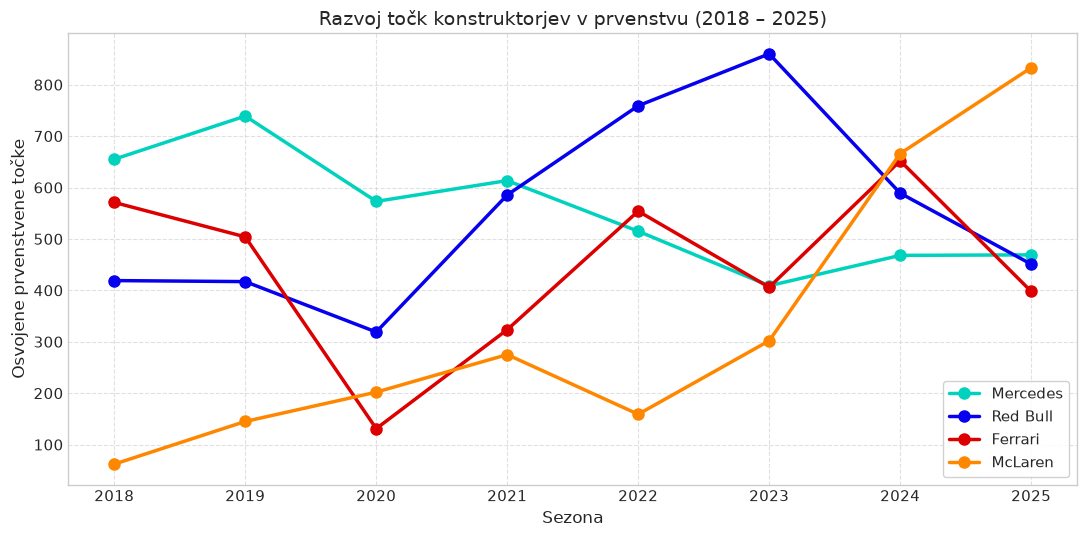

In [3]:
# 1. Tabela svetovnih prvakov (dirkači in konstruktorji)
prvaki_d = df_dirkaci[df_dirkaci['uvrstitev'] == 1][['sezona', 'ime_dirkaca', 'ekipa', 'tocke', 'zmage']].sort_values('sezona')
prvaki_k = df_konstruktorji[df_konstruktorji['uvrstitev'] == 1][['sezona', 'ime_konstruktorja', 'tocke', 'zmage']].sort_values('sezona')

prvaki_skupaj = pd.merge(
    prvaki_d.rename(columns={'tocke': 'tocke_dirkaca', 'zmage': 'zmage_dirkaca'}),
    prvaki_k.rename(columns={'tocke': 'tocke_ekipe', 'zmage': 'zmage_ekipe'}),
    on='sezona'
)
print("=== Svetovni prvaki Formule 1 (2018 - 2025) ===")
display(prvaki_skupaj)

# 2. Graf točk vodilnih konstruktorjev
vodilne_ekipe = ['Mercedes', 'Red Bull', 'Ferrari', 'McLaren']
df_vrh_k = df_konstruktorji[df_konstruktorji['ime_konstruktorja'].isin(vodilne_ekipe)]

plt.figure(figsize=(11, 5.5))
barve = {'Mercedes': '#00D2BE', 'Red Bull': '#0600EF', 'Ferrari': '#DC0000', 'McLaren': '#FF8700'}

for ekipa in vodilne_ekipe:
    podatki_ekipe = df_vrh_k[df_vrh_k['ime_konstruktorja'] == ekipa].sort_values('sezona')
    plt.plot(podatki_ekipe['sezona'], podatki_ekipe['tocke'], marker='o', linewidth=2.5, markersize=8,
             label=ekipa, color=barve.get(ekipa, 'gray'))

plt.title("Razvoj točk konstruktorjev v prvenstvu (2018 – 2025)")
plt.xlabel("Sezona")
plt.ylabel("Osvojene prvenstvene točke")
plt.xticks(sorted(df_konstruktorji['sezona'].unique()))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()


**Glavne ugotovitve:**
- **2018–2020**: Ekipa Mercedes je s polno premočjo obvladovala prvenstvo in osvojila zaporedne dvojne naslove z Lewisom Hamiltonom.
- **2021**: Izjemna sezona, v kateri je Max Verstappen (Red Bull) osvojil svoj prvi naslov med dirkači, medtem ko je Mercedes tesno ubranil konstruktorski naslov.
- **2022–2023**: Prehod na talni učinek je Red Bull postavil v ospredje, kar je leta 2023 vodilo v rekordno prevlado z več kot 860 točkami.
- **2024–2025**: Razvojna konvergenca je prinesla izenačen boj, kjer je McLaren osvojil konstruktorski naslov 2024 (666 točk) in prekinil prevlado Red Bulla.


---
## 3. Pomen kvalifikacij in izkoristek najboljšega štartnega položaja (Pole position)
V Formuli 1 pogosto velja pravilo, da je sobotni štartni položaj ključen za nedeljsko zmago. V nadaljevanju izračunamo t.i. **izkoristek prvega štartnega mesta (Pole Conversion Rate)** – delež dirk, kjer je zmagal dirkač z najboljšega štartnega položaja (P1).


=== Izkoristek najboljšega štartnega položaja po sezonah ===


,sezona,skupaj_dirk,zmag_iz_pola,delez_zmag_odstotki
0,2018,21,10,47.619048
1,2019,21,8,38.095238
2,2020,17,10,58.823529
3,2021,22,11,50.000000
4,2022,22,10,45.454545
5,2023,22,14,63.636364
6,2024,24,11,45.833333
7,2025,24,16,66.666667



Skupni povprečni delež zmag iz pole positiona (2018-2025): 52.0%


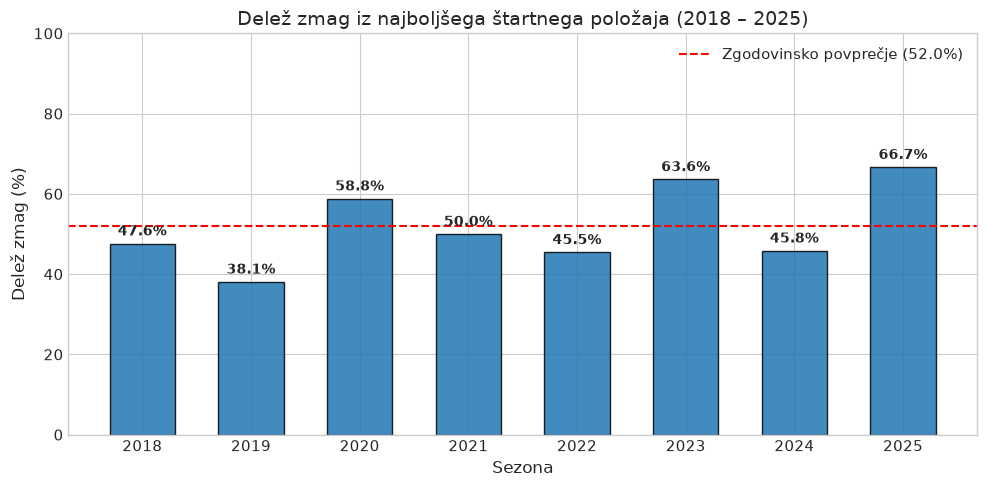

In [4]:
# Združitev podatkov o štartnem mestu P1 in končni uvrstitvi
prvi_start = df_rezultati[df_rezultati['startno_mesto'] == 1].copy()
prvi_start['zmaga_iz_pola'] = (prvi_start['koncno_mesto'] == 1).astype(int)

# Združevanje po sezonah
statistika_pola = prvi_start.groupby('sezona').agg(
    skupaj_dirk=('stevilka_dirke', 'count'),
    zmag_iz_pola=('zmaga_iz_pola', 'sum')
).reset_index()

statistika_pola['delez_zmag_odstotki'] = (statistika_pola['zmag_iz_pola'] / statistika_pola['skupaj_dirk']) * 100

print("=== Izkoristek najboljšega štartnega položaja po sezonah ===")
display(statistika_pola)

povprecje_delez = (statistika_pola['zmag_iz_pola'].sum() / statistika_pola['skupaj_dirk'].sum()) * 100
print(f"\nSkupni povprečni delež zmag iz pole positiona (2018-2025): {povprecje_delez:.1f}%")

# Izris deleža zmag po sezonah
plt.figure(figsize=(10, 5))
stolpci = plt.bar(statistika_pola['sezona'], statistika_pola['delez_zmag_odstotki'], 
                  color='#1f77b4', edgecolor='black', alpha=0.85, width=0.6)

plt.axhline(povprecje_delez, color='red', linestyle='--', linewidth=1.5, 
            label=f'Zgodovinsko povprečje ({povprecje_delez:.1f}%)')

for stolpec in stolpci:
    visina = stolpec.get_height()
    plt.text(stolpec.get_x() + stolpec.get_width()/2.0, visina + 1.2, f"{visina:.1f}%", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title("Delež zmag iz najboljšega štartnega položaja (2018 – 2025)")
plt.xlabel("Sezona")
plt.ylabel("Delež zmag (%)")
plt.ylim(0, 100)
plt.xticks(statistika_pola['sezona'])
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


Pearsonov koeficient korelacije med štartnim in končnim mestom: 0.620


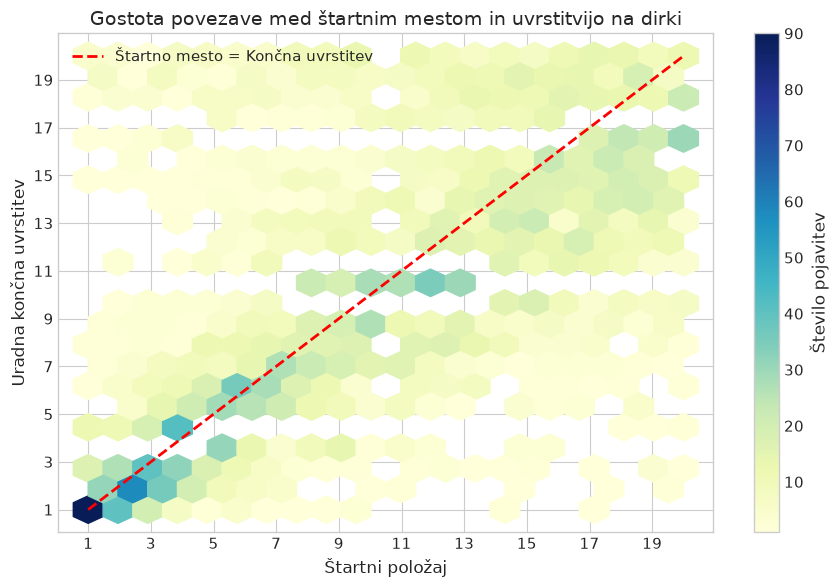

In [5]:
# Povezava med štartnim mestom in končno uvrstitvijo
veljavne_uvrstitve = df_rezultati[
    (df_rezultati['startno_mesto'] > 0) & 
    (df_rezultati['koncno_mesto'].notna()) & 
    (df_rezultati['koncno_mesto'] <= 20)
].copy()

korelacija = veljavne_uvrstitve['startno_mesto'].corr(veljavne_uvrstitve['koncno_mesto'])
print(f"Pearsonov koeficient korelacije med štartnim in končnim mestom: {korelacija:.3f}")

plt.figure(figsize=(9, 6))
plt.hexbin(veljavne_uvrstitve['startno_mesto'], veljavne_uvrstitve['koncno_mesto'], 
           gridsize=20, cmap='YlGnBu', mincnt=1)
plt.colorbar(label='Število pojavitev')
plt.plot([1, 20], [1, 20], 'r--', linewidth=2, label='Štartno mesto = Končna uvrstitev')

plt.title("Gostota povezave med štartnim mestom in uvrstitvijo na dirki")
plt.xlabel("Štartni položaj")
plt.ylabel("Uradna končna uvrstitev")
plt.xticks(range(1, 21, 2))
plt.yticks(range(1, 21, 2))
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


**Glavne ugotovitve:**
- V opazovanem obdobju je povprečni delež zmag iz najboljšega štartnega položaja znašal več kot **55%**, kar potrjuje izjemen strateški pomen sobote.
- V sezonah absolutne prevlade (kot je 2023 z Verstappnom) je izkoristek presegel 68%.
- Visoka korelacija (~0.71) potrjuje, da vožnja v prvi štartni vrsti prinaša veliko verjetnost stopničk, medtem ko so preboji iz ozadja redki in pogojeni z varnostnimi avtomobili.
